# Vinculum 02 · Valuation, profitability and balance-sheet ratios

`fundamentals()` returns four valuation ratios ready-made (`vinculum.RATIOS`). The other ratios
come from `neural-processor`, the signal library: 31 ratios over the 31 EDGAR items (see
`01_fundamentals.ipynb`), plus growth, price and short-interest signals (see `05_signals.ipynb`).
This notebook looks at the ratios:

1. built-in ratios
2. the ratio library
3. well-known companies side by side
4. cross-sectional distributions
5. sectors
6. through time: the market's valuation and profitability since 2012
7. one company, daily
8. caveats

All values are point in time: each month-end row uses only filings available that day, and
market cap is that day's.

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from neural_processor import SIGNALS, Processor, catalogue
from subspace_probe import style, timed
from vinculum import RATIOS, Vinculum

style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(14)
pl.Config.set_fmt_str_lengths(70)
v = Vinculum()
p = Processor(vinculum=v)
RATIO_NAMES = [n for n, s in SIGNALS.items() if s.group in ("value", "profitability", "quality", "leverage")]
with timed(f"{len(RATIO_NAMES)} ratios, month ends 2012-2026"):
    r = p.panel(RATIO_NAMES, start="2012-01-01")
# The panel's largest companies each month (primary class, ranked by issuer market cap).
r = r.with_columns(pl.col("issuer_market_cap").rank("ordinal", descending=True).over("date").alias("size_rank"))
print(f"{r.height:,} rows, {r['cik'].n_unique():,} companies")

31 ratios, month ends 2012-2026: 39.81 s
926,498 rows, 11,116 companies


## 1 · Built-in ratios

Each is a TTM flow or the latest balance sheet over **issuer market cap** (the whole company,
every share class), computed only for USD reporters:

In [2]:
pl.DataFrame({"ratio": list(RATIOS), "numerator": list(RATIOS.values()),
              "meaning": ["inverse P/E", "inverse P/B", "inverse P/S", "inverse P/CF"]})

ratio,numerator,meaning
str,str,str
"""earnings_yield""","""net_income""","""inverse P/E"""
"""book_to_market""","""equity""","""inverse P/B"""
"""sales_to_price""","""revenue""","""inverse P/S"""
"""cash_flow_yield""","""operating_cash_flow""","""inverse P/CF"""


## 2 · The ratio library

`neural_processor.SIGNALS` holds each ratio's formula, the EDGAR items it needs and the
direction the literature expects (+1: higher has gone with higher returns). `Processor.panel()`
loads only the items the requested signals need. Rules used throughout:

- A ratio over market cap or enterprise value needs a USD reporter (no FX conversion).
  Within-company ratios (margins, returns, leverage) use one filing's currency and work for
  every company.
- A denominator must be positive: ROE of a company with negative equity, or a margin on zero
  revenue, is missing rather than a misleading sign flip.
- Enterprise value is approximated as market cap + long-term debt + short-term borrowings −
  cash (no leases, preferred stock or minority interest among the items). `debt_current` is
  left out because `long_term_debt` usually includes current maturities already.
- Missing `dividends_paid`, `buybacks` and `capex` stay missing. Zero would be right for a
  company that returns no cash, but wrong for one that files the number under a tag outside the
  catalogue (see 01). So dividend yield and free-cash-flow yield cover fewer companies than
  earnings yield does.
- Returns use TTM flows over the latest balance sheet, not an average of two.

In [3]:
catalogue().filter(pl.col("name").is_in(RATIO_NAMES)).select("name", "group", "formula", "direction", "note")

name,group,formula,direction,note
str,str,str,i64,str
"""earnings_yield""","""value""","""net income / market cap (inverse P/E)""",1,""""""
"""book_to_market""","""value""","""equity / market cap""",1,""""""
"""sales_to_price""","""value""","""revenue / market cap""",1,""""""
"""cash_flow_yield""","""value""","""operating cash flow / market cap""",1,""""""
"""fcf_yield""","""value""","""(operating cash flow - capex) / market cap""",1,""""""
"""dividend_yield""","""value""","""dividends paid / market cap""",1,""""""
"""shareholder_yield""","""value""","""(dividends + buybacks) / market cap; a missing one counts as 0""",1,""""""
"""ebit_to_ev""","""value""","""operating income / EV""",1,""""""
"""ebitda_to_ev""","""value""","""(operating income + D&A) / EV""",1,""""""


A signal of your own is one more polars expression over the same panel. The items a
`Processor` panel loads are not in its output, so load them with `vinculum.fundamentals()` and
join, or compute from existing signals, e.g. a P/E from the earnings yield:

In [4]:
r.select("date", "ticker", "earnings_yield").with_columns(
    pl.when(pl.col("earnings_yield") > 0).then(1 / pl.col("earnings_yield")).alias("pe")).filter(
    pl.col("ticker") == "AAPL").tail(3)

date,ticker,earnings_yield,pe
date,str,f64,f64
2026-09-30,"""AAPL""",0.026501,37.73425
2026-10-30,"""AAPL""",0.025608,39.049771
2026-11-02,"""AAPL""",0.026086,38.334789


## 3 · Well-known companies side by side

The latest month end. Reading down a column is a quick health check of the data:
- Apple's gross margin is near 49%, Nvidia's operating margin above 60%.
- Coca-Cola pays out most of its earnings.
- JPMorgan has no gross or operating margin: banks have no such lines.
- Gaps follow the items' coverage: no SG&A ratio for Amazon (no single SG&A line), no
  interest coverage for Apple (no interest expense line since 2024), no total liabilities for
  Walmart or Coca-Cola.

In [5]:
last = r["date"].max()
names = ["AAPL", "MSFT", "NVDA", "AMZN", "TSLA", "JPM", "KO", "WMT", "CVX", "PFE"]
snap = r.filter((pl.col("date") == last) & pl.col("ticker").is_in(names))
table = snap.to_pandas().set_index("ticker").loc[[n for n in names if n in snap["ticker"]], RATIO_NAMES].T
print(f"as known on {last}")
table.round(3)

as known on 2026-11-02


ticker,AAPL,MSFT,NVDA,AMZN,TSLA,JPM,KO,WMT,CVX,PFE
earnings_yield,0.026,0.038,0.040,0.051,0.002,0.072,0.035,0.022,0.046,0.025
book_to_market,0.022,0.125,0.047,0.231,0.056,0.414,0.091,0.097,0.422,0.487
sales_to_price,0.094,0.092,0.062,0.300,0.065,0.220,0.124,0.726,0.478,0.364
cash_flow_yield,0.030,0.052,0.028,0.063,0.012,-0.180,0.039,0.042,0.101,0.077
fcf_yield,0.028,0.016,0.026,-0.018,0.002,NaN,0.035,0.013,0.060,0.063
dividend_yield,0.003,0.007,0.001,NaN,NaN,0.019,0.027,0.008,0.031,0.056
shareholder_yield,0.020,0.013,0.013,NaN,NaN,0.054,0.030,0.014,0.056,0.056
ebit_to_ev,0.031,0.043,0.040,0.038,0.002,NaN,0.038,0.031,NaN,NaN
ebitda_to_ev,0.034,NaN,0.041,0.066,NaN,NaN,0.041,0.045,NaN,NaN
sales_to_ev,0.094,0.092,0.062,0.287,0.065,0.299,0.128,0.702,0.488,0.272


## 4 · Cross-sectional distributions

The 1,000 largest companies on the latest month end, each ratio clipped to its 1st-99th
percentile for the plot. Ratios with a small denominator (ROE near zero equity, EV near zero
for cash-rich companies) have long tails; rank or winsorize them before using them as signals.

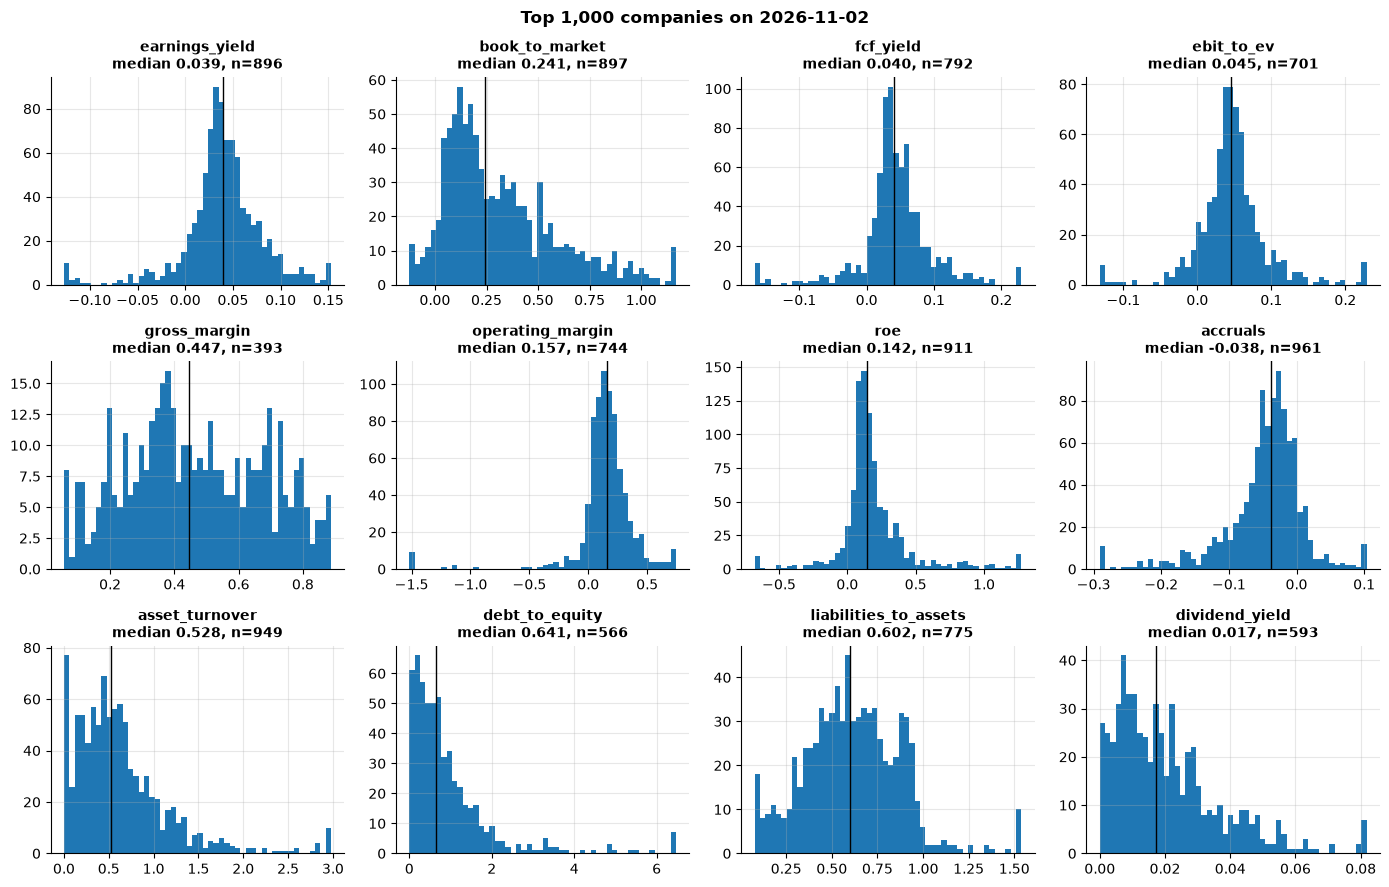

In [6]:
top = r.filter((pl.col("date") == last) & (pl.col("size_rank") <= 1000))
show = ["earnings_yield", "book_to_market", "fcf_yield", "ebit_to_ev",
        "gross_margin", "operating_margin", "roe", "accruals",
        "asset_turnover", "debt_to_equity", "liabilities_to_assets", "dividend_yield"]
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, name in zip(axes.flat, show, strict=True):
    s = top[name].drop_nulls()
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    ax.hist(s.clip(lo, hi), bins=50)
    ax.axvline(s.median(), color="black", lw=1)
    ax.set_title(f"{name}\nmedian {s.median():.3f}, n={s.len()}", fontsize=10)
fig.suptitle(f"Top 1,000 companies on {last}", fontweight="bold")
fig.tight_layout()
plt.show()

In [7]:
pl.DataFrame({"ratio": show,
              "coverage": [top[n].is_not_null().mean() for n in show],
              "negative": [(top[n] < 0).mean() for n in show],
              "p01": [top[n].quantile(0.01) for n in show],
              "median": [top[n].median() for n in show],
              "p99": [top[n].quantile(0.99) for n in show]}).with_columns(pl.col(pl.Float64).round(3))

ratio,coverage,negative,p01,median,p99
str,f64,f64,f64,f64,f64
"""earnings_yield""",0.896,0.097,-0.127,0.039,0.153
"""book_to_market""",0.897,0.056,-0.124,0.241,1.169
"""fcf_yield""",0.792,0.101,-0.166,0.04,0.23
"""ebit_to_ev""",0.701,0.093,-0.132,0.045,0.229
"""gross_margin""",0.393,0.0,0.057,0.447,0.887
"""operating_margin""",0.744,0.09,-1.519,0.157,0.746
"""roe""",0.911,0.09,-0.678,0.142,1.273
"""accruals""",0.961,0.88,-0.291,-0.038,0.104
"""asset_turnover""",0.949,0.0,0.001,0.528,2.978


## 5 · Sectors

Sector from the company's SIC code (EDGAR profiles), grouped into the Fama-French 12
industries. SIC is today's code, not point in time, which rarely matters for large companies.
Medians across the top 1,000:

In [8]:
by_sector = (top.filter(pl.col("sector").is_not_null()).group_by("sector")
             .agg(pl.len().alias("companies"), pl.col("gross_margin").is_not_null().mean().alias("has_gross_margin"),
                  *[pl.col(c).median() for c in ["gross_margin", "operating_margin", "roe", "earnings_yield",
                                                 "book_to_market", "dividend_yield", "debt_to_equity",
                                                 "liabilities_to_assets", "asset_turnover"]])
             .sort("companies", descending=True).with_columns(pl.col(pl.Float64).round(3)))
by_sector

sector,companies,has_gross_margin,gross_margin,operating_margin,roe,earnings_yield,book_to_market,dividend_yield,debt_to_equity,liabilities_to_assets,asset_turnover
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Finance""",202,0.069,0.61,0.22,0.12,0.058,0.493,0.024,0.651,0.811,0.141
"""Business equipment""",185,0.708,0.635,0.157,0.153,0.025,0.134,0.008,0.462,0.468,0.562
"""Other""",145,0.255,0.382,0.173,0.181,0.039,0.197,0.011,0.804,0.627,0.591
"""Manufacturing""",103,0.621,0.363,0.154,0.165,0.036,0.211,0.011,0.531,0.565,0.69
"""Healthcare""",94,0.351,0.644,0.135,0.112,0.025,0.164,0.01,0.657,0.504,0.555
"""Shops""",73,0.63,0.312,0.086,0.248,0.047,0.144,0.018,0.719,0.694,1.475
"""Utilities""",56,0.0,null,0.239,0.103,0.048,0.444,0.029,1.448,0.733,0.2
"""Consumer non-durables""",40,0.85,0.423,0.147,0.147,0.043,0.339,0.029,0.695,0.645,0.64
"""Energy""",36,0.083,0.349,0.19,0.125,0.067,0.576,0.022,0.271,0.481,0.51


The familiar patterns show up:
- **Finance** has the most liabilities per unit of assets (banks fund themselves with
  deposits) and the slowest asset turnover. Only 7% of financial companies report a gross
  margin, so that median describes a few exchanges and payment companies, not banks.
- **Business equipment** (technology) and **Healthcare** have the highest gross margins;
  technology has the lowest book-to-market, with retail and healthcare close behind.
- **Energy** has the highest book-to-market, and with **Telecom** the highest earnings yield.
- **Utilities** carry the most debt per unit of equity (Telecom next). Telecom, consumer
  staples and utilities pay the highest dividends. No utility reports a gross profit line.
- **Shops** (retail and wholesale) turn their assets over fastest, on thin operating margins.

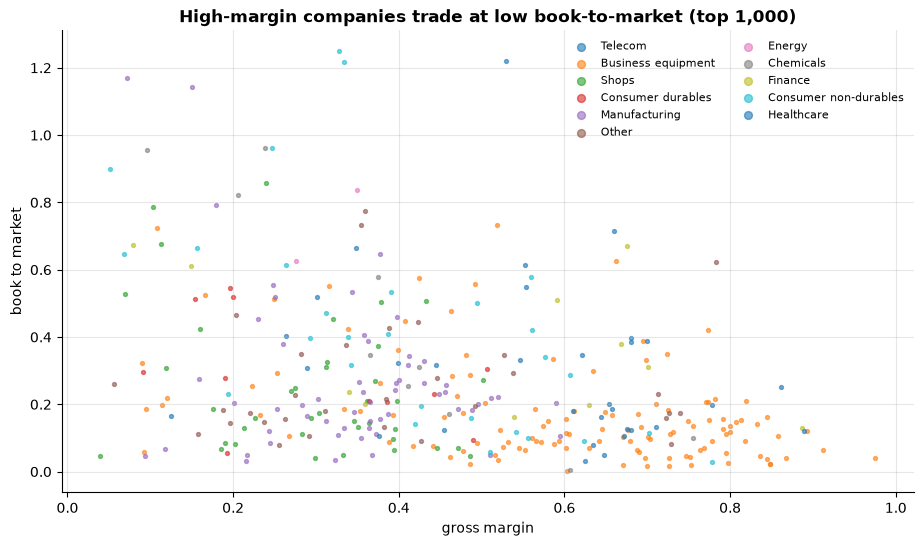

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
pts = top.filter(pl.col("sector").is_not_null() & pl.col("gross_margin").is_between(-0.5, 1)
                 & pl.col("book_to_market").is_between(0, 3))
for name, g in pts.group_by("sector"):
    ax.scatter(g["gross_margin"], g["book_to_market"], s=8, alpha=0.6, label=name[0])
ax.set_xlabel("gross margin")
ax.set_ylabel("book to market")
ax.set_title("High-margin companies trade at low book-to-market (top 1,000)")
ax.legend(fontsize=8, ncol=2, markerscale=2)
plt.show()

## 6 · Through time

Medians across the 500 largest companies each month end (ranked by issuer market cap within
the panel), and the aggregate P/E (total market cap / total TTM net income of the same 500,
USD reporters), which is what an index P/E measures.

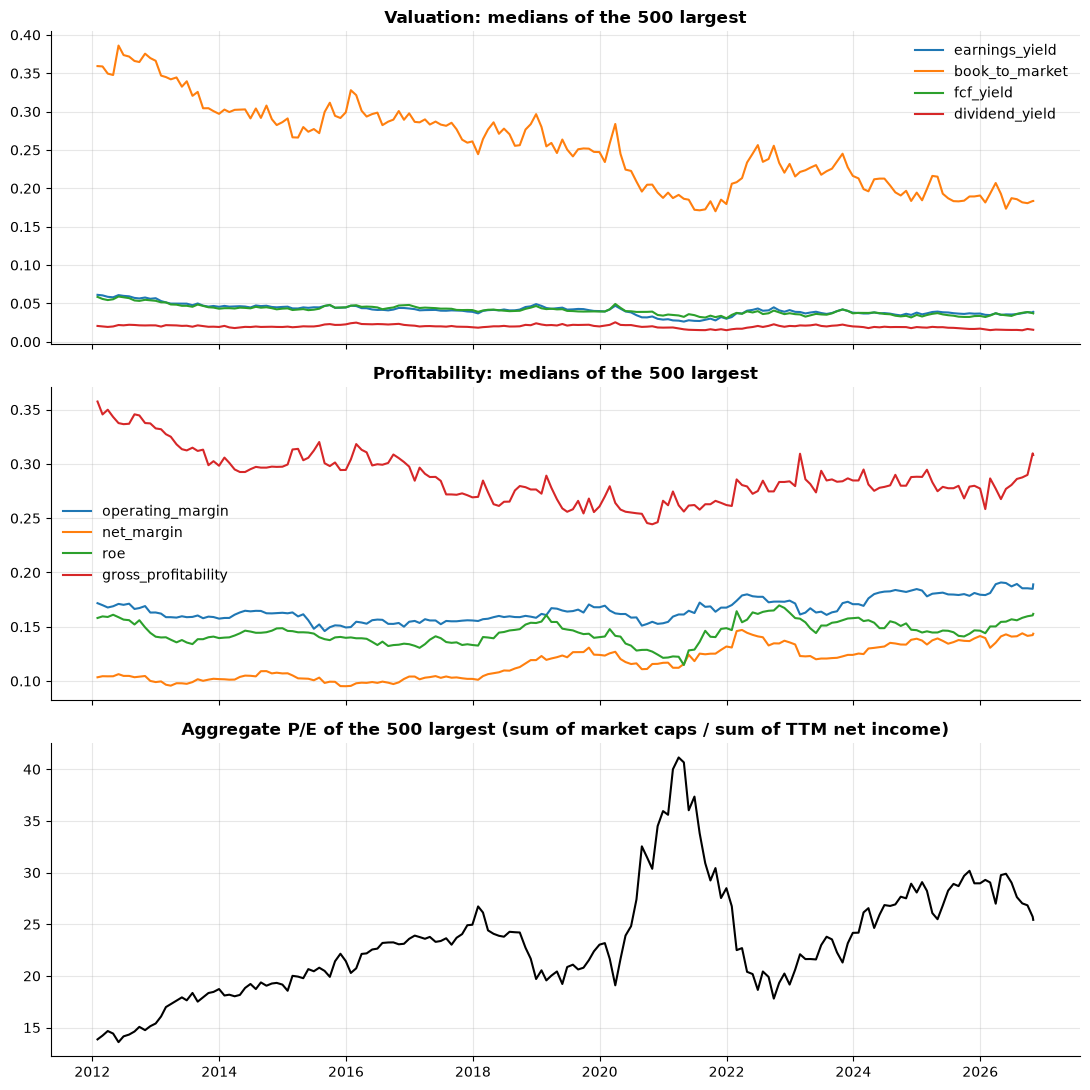

In [10]:
big = r.filter(pl.col("size_rank") <= 500)
med = big.group_by("date").agg(
    *[pl.col(c).median() for c in ["earnings_yield", "book_to_market", "fcf_yield", "dividend_yield",
                                   "operating_margin", "net_margin", "roe", "gross_profitability"]],
    (pl.col("issuer_market_cap").filter(pl.col("earnings_yield").is_not_null()).sum()
     / (pl.col("earnings_yield") * pl.col("issuer_market_cap")).sum()).alias("aggregate_pe")).sort("date")
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for c in ["earnings_yield", "book_to_market", "fcf_yield", "dividend_yield"]:
    axes[0].plot(med["date"], med[c], label=c)
axes[0].set_title("Valuation: medians of the 500 largest")
axes[0].legend()
for c in ["operating_margin", "net_margin", "roe", "gross_profitability"]:
    axes[1].plot(med["date"], med[c], label=c)
axes[1].set_title("Profitability: medians of the 500 largest")
axes[1].legend()
axes[2].plot(med["date"], med["aggregate_pe"], color="black")
axes[2].set_title("Aggregate P/E of the 500 largest (sum of market caps / sum of TTM net income)")
fig.tight_layout()
plt.show()

In [11]:
med.filter(pl.col("date").dt.month() == 12).select(
    pl.col("date").dt.year().alias("year"), pl.col("aggregate_pe").round(1),
    (1 / pl.col("earnings_yield")).round(1).alias("median_pe"), pl.col("dividend_yield").round(4),
    pl.col("operating_margin").round(3))

year,aggregate_pe,median_pe,dividend_yield,operating_margin
i32,f64,f64,f64,f64
2012,15.4,17.6,0.0214,0.163
2013,18.7,21.9,0.0193,0.158
2014,19.2,22.0,0.0193,0.163
2015,21.4,22.3,0.0227,0.149
2016,23.6,23.1,0.0214,0.155
2017,25.0,25.6,0.019,0.156
2018,19.7,20.4,0.0241,0.158
2019,23.0,25.0,0.02,0.168
2020,36.0,34.6,0.0184,0.153


The aggregate P/E tracks the published S&P 500 trailing P/E:
- mid-teens in 2012;
- high 30s at the end of 2020, when pandemic earnings collapsed;
- back below 20 after the 2022 sell-off;
- near 29 in 2025.

Operating margins of the largest companies rose from about 16% to 18%. The median dividend
yield is over companies reporting dividends, so it reads higher than an index yield.

## 7 · One company, daily

With `freq="1d"` every trading day gets a row: the price moves the ratio daily, and each filing
moves it in a step. Apple's P/E (1 / earnings yield) and the TTM net income behind it:

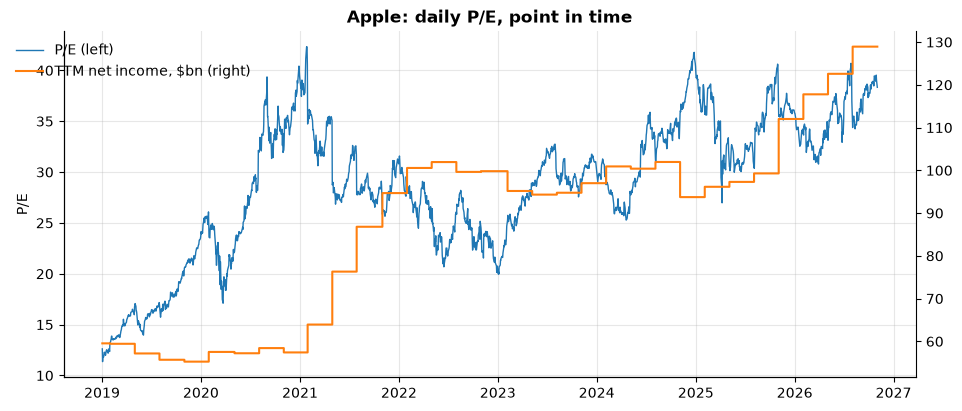

In [12]:
a = v.fundamentals(["net_income", "equity"], start="2019-01-01", tickers="AAPL", freq="1d")
fig, ax = plt.subplots()
ax.plot(a["date"], 1 / a["earnings_yield"], lw=1, label="P/E (left)")
ax.set_ylabel("P/E")
ax2 = ax.twinx()
ax2.step(a["date"], a["net_income"] / 1e9, where="post", color="tab:orange", label="TTM net income, $bn (right)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Apple: daily P/E, point in time")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.show()

## 8 · Caveats

- **Banks, insurers, REITs.** Revenue means different things (see 01), there is no gross profit
  or operating income for banks, and debt ratios are not comparable with industrial companies.
  Compare within a sector, or exclude Finance for margin and EV ratios.
- **Enterprise value is approximate**: no leases, preferred or minority interest; companies
  without a `long_term_debt` tag count as debt-free, and for the few whose `long_term_debt`
  excludes current maturities, those are missing.
- **Shareholder yield** treats missing dividends or buybacks as zero (it needs one of the two).
- **USD reporters only** for anything over market cap; foreign filers' within-company ratios
  are fine, apart from the known issue with convenience translations described in 01.
- **Multi-class companies** are valued through their primary class: `issuer_market_cap`
  covers all classes, so ratios are company-wide. Companies without a company-wide share count
  (Berkshire after 2016) have no market cap and so no valuation ratios.
- **Point in time but not survivorship-filtered here**: the 500/1,000 largest are chosen each
  month from what existed then, so delisted companies are included while they traded.
- **Sector is today's SIC**, and the 12-industry grouping is coarse.